# 08 円環道路の定常状態ソルバー（ダミーデータ検証の共通道具）と Q1 ①②

**目的**: s の符号が不安定な原因を「Q1 式そのもの / Q2 推定誤差 / Q3 条件」に切り分けるため、正解の分かる円環道路の名目速度関数を作る。
このノートブックでは共通の道具 `src/ring_equilibrium.py`（層1〜3）の動作確認と、**Q1 ①（導出・実装の確認）**、**Q1 ②a・②b（仮定を崩したときの影響）** を行う。

- 円環の定常状態では同じ車線の全車が同じ速度 v で走るので、正解の1-pipe速度は $\sum_{ij} n_{ij} h_{ij}(v) = L$ の解。
- 円環では C-T ペア数 = T-C ペア数 = m（トラックの塊の数）。ランダム混合 $m = n_1 n_2/N$ と論文形 $u_{ij}(\rho)=u_i(\rho/a_j)$ を入れると、この式は**印刷版 Eq.7 そのもの**になる。
- 名目速度関数は2つ: **論文形の名目速度関数**（論文形。Table 4・5）と **OV形の名目速度関数**（OV関数の一般形。速度は先行車との隙間 $h-\ell_j$ で決まる）。

In [2]:
import sys, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2
sys.path.append(os.path.abspath(".."))

from src.ring_equilibrium import (CAR, TRUCK, PAIRS, make_paper_nominal, make_ov_nominal, OV_SHAPE,
                                  h_eq, v_eq, v_range, u_nominal, R_eq,
                                  pair_counts, m_range, lane_speed, at_speed_cap, ring_state, true_1pipe_speed,
                                  separated_speeds, surplus_at, separation_speed, eq7_speed)

KM_TO_MILE = 1.60934
OUT = Path("../results/dummy_ring_2026-10-31"); OUT.mkdir(parents=True, exist_ok=True)

#論文 Table 4（mph, vpm → km/h, veh/km に換算。θ1 は密度と同じ単位なので vpm→veh/km）
CAR_PARAMS = {'ub': 7.93 * KM_TO_MILE, 'uf': 73.55 * KM_TO_MILE, 'rhoc': 20.40 / KM_TO_MILE,
              'theta1': 8.0387 / KM_TO_MILE, 'theta2': 0.2309}
TRUCK_PARAMS = {'uf': 42.55 * KM_TO_MILE, 'rhoc': 41.74 / KM_TO_MILE}
A2_PAPER, B1_PAPER = 0.4528, 2.5996   #Table 5（無次元なので換算不要）

## 1. 名目速度関数の定義

| 名目速度関数 | 定義 | 仮定1（形） | 仮定2（スケーリング） |
|---|---|---|---|
| 論文形の名目速度関数 | $u_{ij}(\rho)=u_i(\rho/a_j)$、乗用車 logistic・トラック Underwood | 満たす | 満たす |
| OV形（gap） | $V_i(x)=v_{0,i}[\tanh(x/l_0-2)+\tanh 2]$、$x = h-\ell_j$ | 満たさない | 満たさない |

OV形は一般形 $\tanh(x-2)+\tanh 2$ に長さの尺度 $l_0$ と速度の尺度 $v_{0,i}$ を入れたもの。隙間 0 で停止する。
クラスで変えるのは**最高速度（乗用車 120 km/h、トラック 90 km/h）と車長（乗用車 4.5 m、トラック 12 m）だけ**で、運転の仕方は先行車によらない。$l_0=12.5$ m を含め、値はすべて仮置き。

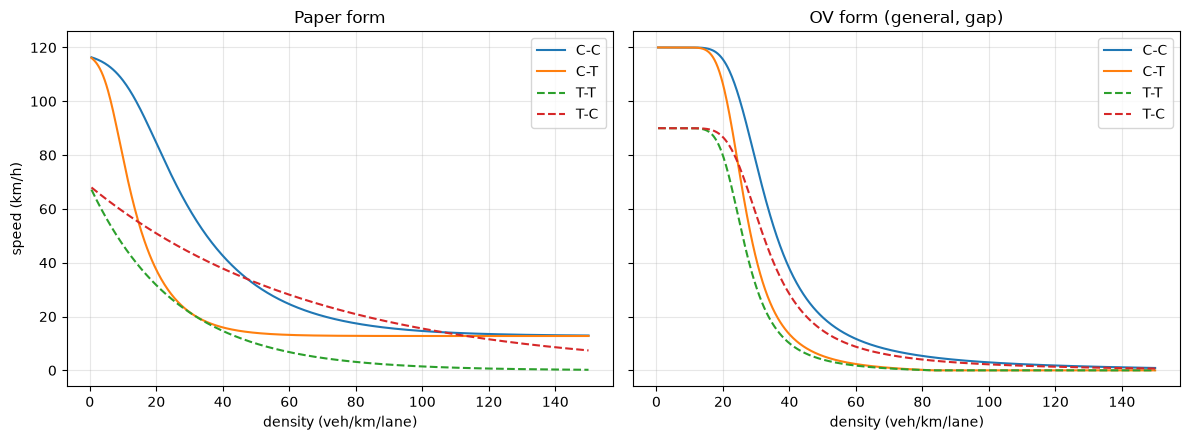

car  : vmax= 120.0 km/h, capacity= 2520 veh/h/lane at 25.0 veh/km, jam density=222.2 veh/km
truck: vmax=  90.0 km/h, capacity= 1598 veh/h/lane at 20.2 veh/km, jam density=83.3 veh/km
C-C: jam spacing h(v=0) = 4.50 m
C-T: jam spacing h(v=0) = 12.00 m
T-T: jam spacing h(v=0) = 12.00 m
T-C: jam spacing h(v=0) = 4.50 m


In [ ]:
pm = make_paper_nominal(CAR_PARAMS, TRUCK_PARAMS, A2_PAPER, B1_PAPER)
ovm = make_ov_nominal()   #既定: 一般形、vmax 乗用車120/トラック90 km/h、車長 4.5/12 m、l0=12.5 m、form='gap'

LABEL = {(1, 1): 'C-C', (1, 2): 'C-T', (2, 2): 'T-T', (2, 1): 'T-C'}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
rho = np.linspace(0.5, 150, 600)#0.5~150km/hを600点に分けた配列で横軸を作る
#曲線を描く
for ax, (name, w) in zip(axes, [('Paper form', pm), ('OV form (general, gap)', ovm)]):
    for p in PAIRS:
        ax.plot(rho, u_nominal(w, *p, rho), label=LABEL[p], ls='-' if p[0] == CAR else '--')
    ax.set_title(name); ax.set_xlabel('density (veh/km/lane)'); ax.grid(alpha=.3); ax.legend()
axes[0].set_ylabel('speed (km/h)')
plt.tight_layout(); plt.savefig(OUT / 'true_curves.png', dpi=130); plt.show()

#OV形の名目速度関数 の基本図の大きさ（容量・渋滞密度）が現実的かの確認
for i, name in [(CAR, 'car'), (TRUCK, 'truck')]:
    q = rho * u_nominal(ovm, i, i, rho)#流量
    print(f"{name:5s}: vmax={ovm['vmax'][i]:6.1f} km/h, capacity={q.max():5.0f} veh/h/lane at {rho[q.argmax()]:.1f} veh/km, "
          f"jam density={R_eq(ovm, i, i, 1e-9):.1f} veh/km")
for p in PAIRS:
    print(f"{LABEL[p]}: jam spacing h(v=0) = {h_eq(ovm, *p, 1e-9):.2f} m")

## 2. 道具の検算

- (b-1) すべての名目速度関数・ペアで $V_{ij}(h_{ij}(v)) = v$（逆関数の往復）。
- (b-2) 乗用車だけの円環: 速度が $V_{11}(L/n)$ に一致する。
- (b-3) 混走の並びを実際に作って隣り合う組を数えると、`pair_counts` に一致する。
- (b-4) 混走の円環を $dv/dt=a[V(h)-v]$ で時間発展させると、落ち着いた速度が `lane_speed` に一致する（`pair_counts` も `lane_speed` も使わない確認）。

In [ ]:
#h_eq(速度→車間を求める)とv_eq(車間->速度を求める)が互いに逆関数になるか
for name, w in [('Paper', pm), ('OV', ovm)]:
    for p in PAIRS:
        lo, hi = v_range(w, *p)
        v = np.linspace(lo + 1, hi - 1, 200)#計算可能な範囲で200点
        err = np.max(np.abs(v_eq(w, *p, h_eq(w, *p, v)) - v))#速度→車間→速度-速度＝０？
        assert err < 1e-6, (name, p, err)
print('(b-1) 逆関数の往復 OK')

#乗用車だけの円環
for L in [100, 200, 300, 400]:
    v = lane_speed(ovm, pair_counts(10, 0, 0), L)#乗用車10台トラック0台の円環　周長(密度)を変えてlane_speedを解く
    print(f"(b-2) car-only, n=10, L={L} m: ring v={v:7.3f}  V11(L/n)={float(v_eq(ovm, 1, 1, L / 10)):7.3f}")

(b-1) 逆関数の往復 OK
(b-2) car-only, n=10, L=100 m: ring v=  2.970  V11(L/n)=  2.970
(b-2) car-only, n=10, L=200 m: ring v= 19.732  V11(L/n)= 19.732
(b-2) car-only, n=10, L=300 m: ring v= 61.344  V11(L/n)= 61.344
(b-2) car-only, n=10, L=400 m: ring v=100.803  V11(L/n)=100.803


In [ ]:
#実際の並びから隣り合う組を1組ずつ数える
def count_pairs(order):
    counts = {p: 0 for p in PAIRS}
    for k in range(len(order)):
        counts[(order[k], order[(k + 1) % len(order)])] += 1
    return counts


#lane_speed も pair_counts も使わず、dv/dt = a[V(h) − v] で車両を動かす
def simulate_ring(nominal, order, L, a=5.0, dt=0.05, T=2000.0, seed=0):
    order = np.array(order)
    n = len(order)
    lead = (np.arange(n) + 1) % n
    x = np.arange(n) * L / n + np.random.default_rng(seed).normal(0, 0.3, n)   #初期位置を少し乱す
    v = np.full(n, 5.0)   #m/s
    for _ in range(int(T / dt)):
        h = (x[lead] - x) % L
        target = np.zeros(n)
        for i, j in PAIRS:
            mask = (order == i) & (order[lead] == j)
            if mask.any():
                target[mask] = v_eq(nominal, i, j, h[mask]) / 3.6
        v = np.maximum(v + dt * a * (target - v), 0.0)
        x = x + dt * v
    return v * 3.6   #km/h


ORDERS = {1: [CAR] * 8 + [TRUCK] * 2,                           #m=1: 隊列
          2: [CAR] * 4 + [TRUCK] + [CAR] * 4 + [TRUCK]}         #m=2: トラックが分散

for m, order in ORDERS.items():
    assert count_pairs(order) == pair_counts(8, 2, m), m
print('(b-3) 並びから数えたペア数 = pair_counts OK')

ovm_scale = make_ov_nominal(form='scale', scale={(1, 2): 0.6, (2, 1): 1.5})
for name, w in [('Paper', pm), ('OV gap', ovm), ('OV scale', ovm_scale)]:
    for m, order in ORDERS.items():
        for L in [250, 400]:
            v_ring = lane_speed(w, pair_counts(8, 2, m), L)
            v_sim = simulate_ring(w, order, L)
            assert np.max(np.abs(v_sim - v_ring)) < 1e-6, (name, m, L)
            print(f"(b-4) {name:8s} m={m} L={L} m: ring v={v_ring:7.3f}  sim v={v_sim.mean():7.3f}")

(b-3) 並びから数えたペア数 = pair_counts OK
(b-4) Paper    m=1 L=250 m: ring v= 31.126  sim v= 31.126
(b-4) Paper    m=1 L=400 m: ring v= 47.738  sim v= 47.738
(b-4) Paper    m=2 L=250 m: ring v= 32.095  sim v= 32.095
(b-4) Paper    m=2 L=400 m: ring v= 50.844  sim v= 50.844
(b-4) OV gap   m=1 L=250 m: ring v= 29.776  sim v= 29.776
(b-4) OV gap   m=1 L=400 m: ring v= 86.668  sim v= 86.668
(b-4) OV gap   m=2 L=250 m: ring v= 29.776  sim v= 29.776
(b-4) OV gap   m=2 L=400 m: ring v= 86.668  sim v= 86.668
(b-4) OV scale m=1 L=250 m: ring v= 28.240  sim v= 28.240
(b-4) OV scale m=1 L=400 m: ring v= 85.769  sim v= 85.769
(b-4) OV scale m=2 L=250 m: ring v= 26.830  sim v= 26.830
(b-4) OV scale m=2 L=400 m: ring v= 84.581  sim v= 84.581


## 3. Q1 ①: 論文の仮定どおりの名目速度関数で Eq.7 は正解と一致するか

論文形の名目速度関数 の名目速度関数・ランダム混合の並びで、正解 $v_{true}$ と Eq.7 の u*（印刷版・反転版）を $(\rho_1, \rho_2)$ の格子上で比べる。
予想: 印刷版は計算誤差の範囲で一致、反転版はずれる。

printed : max|u* - v_true| = 2.70e-13 km/h
inverted: max|u* - v_true| = 15.83 km/h, mean = -7.18 km/h


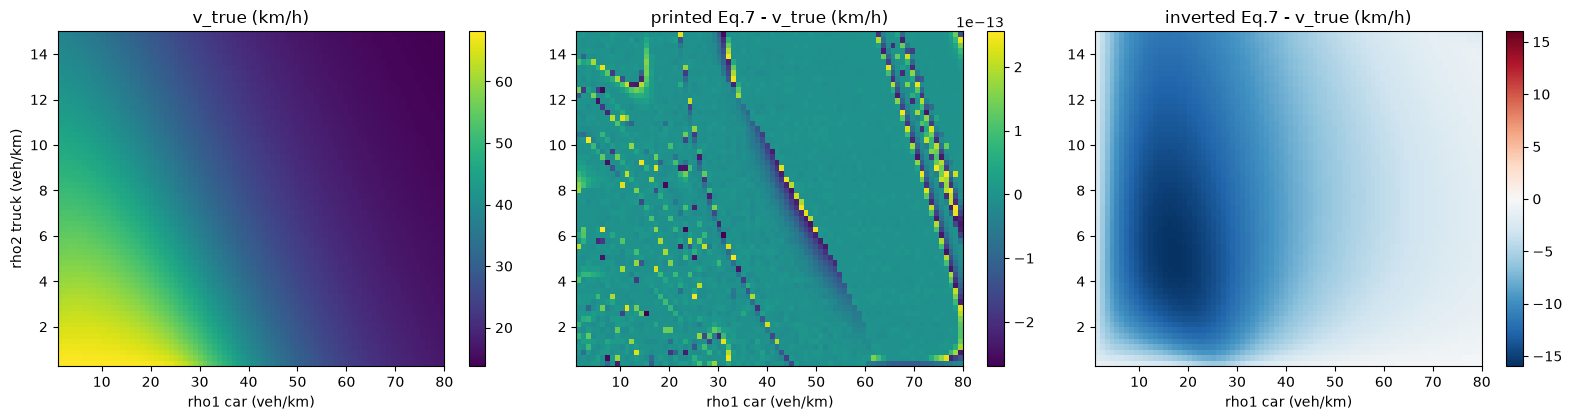

In [10]:
#調べる密度の格子を作る
r1s = np.linspace(1, 80, 80)
r2s = np.linspace(0.25, 15, 60)

#正解の速度を計算する
V = np.full((len(r2s), len(r1s)), np.nan)
for b, r2 in enumerate(r2s):
    for a, r1 in enumerate(r1s):
        V[b, a] = true_1pipe_speed(pm, r1, r2)#1組ずつ1-pipe速度を解く　ランダム混合の時の
UP = eq7_speed(pm, r1s[None, :], r2s[:, None], 'printed')#eq(7)の速度を計算　印刷版
UI = eq7_speed(pm, r1s[None, :], r2s[:, None], 'inverted')#反転版

#正解との差を集計
dP, dI = UP - V, UI - V
print(f"printed : max|u* - v_true| = {np.nanmax(np.abs(dP)):.2e} km/h")
print(f"inverted: max|u* - v_true| = {np.nanmax(np.abs(dI)):.2f} km/h, mean = {np.nanmean(dI):.2f} km/h")

#グラフを描く
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
ext = [r1s[0], r1s[-1], r2s[0], r2s[-1]]
for ax, Z, t, kw in [(axes[0], V, 'v_true (km/h)', {}),
                     (axes[1], dP, 'printed Eq.7 - v_true (km/h)', {}),
                     (axes[2], dI, 'inverted Eq.7 - v_true (km/h)', {'cmap': 'RdBu_r', 'vmin': -16, 'vmax': 16})]:
    im = ax.imshow(Z, origin='lower', aspect='auto', extent=ext, **kw)
    plt.colorbar(im, ax=ax); ax.set_title(t); ax.set_xlabel('rho1 car (veh/km)')
axes[0].set_ylabel('rho2 truck (veh/km)')
plt.tight_layout(); plt.savefig(OUT / 'q1_step1_eq7_vs_truth.png', dpi=130); plt.show()

**結果**: 印刷版 Eq.7 は円環の正解と計算誤差の範囲で一致する。反転版は最大約 15 km/h 低い。
→ 定義 $u_{ij}(\rho)=u_i(\rho/a_j)$ のもとで物理的に正しいのは**印刷版**。論文の図（反転版で再現できる）は、この定義と整合しない計算で描かれている可能性が高い。

## 4. 参考: ②a・②b の予告（並び m の影響と、OV形の名目速度関数 での s）

同じ $(\rho_1,\rho_2)$ で並び m だけを変えたときの正解の速度と、OV形（gap）での s。

In [5]:
rows = []
for name, w in [('Paper', wp), ('OV gap', wo)]:
    for r1, r2 in [(10, 2), (20, 4), (40, 8), (10, 10), (60, 5)]:
        vt = true_1pipe_speed(w, r1, r2)
        capped = at_speed_cap(w, r1, r2, vt)   #上限に張り付いた点の s は数値的に決まらないので NaN にする
        rows.append({'nominal': name, 'rho1': r1, 'rho2': r2,
                     'v_true(random m)': vt,
                     'v_true(m=0.2*min)': true_1pipe_speed(w, r1, r2, m_per_km=0.2 * min(r1, r2)),
                     'v_true(m=min)': true_1pipe_speed(w, r1, r2, m_per_km=min(r1, r2)),
                     'u_sep': separation_speed(w, r1, r2),
                     'at_cap': capped,
                     's_true': np.nan if capped else float(surplus_at(w, r1, r2, vt)['s'])})
pd.DataFrame(rows).round(3)

,nominal,rho1,rho2,v_true(random m),v_true(m=0.2*min),v_true(m=min),u_sep,at_cap,s_true
0,Paper,10,2,64.121,61.618,64.894,60.936,False,-0.530
1,Paper,20,4,52.661,49.277,53.878,48.456,False,-0.181
2,Paper,40,8,26.351,25.769,26.518,25.599,False,-0.024
3,Paper,10,10,43.608,42.032,47.277,41.138,False,-0.109
4,Paper,60,5,20.102,19.915,20.122,19.864,False,-0.010
5,OV gap,10,2,90.000,90.000,90.000,90.000,True,NaN
6,OV gap,20,4,89.387,89.387,89.387,89.387,False,-0.000
7,OV gap,40,8,17.658,17.658,17.658,17.658,False,0.000
8,OV gap,10,10,88.762,88.762,88.762,88.762,False,0.000
9,OV gap,60,5,8.242,8.242,8.242,8.242,False,0.000


- **論文形の名目速度関数**: 並び m によって正解の速度が数 km/h 変わる（例: $(10,10)$ で約 5 km/h）。s は u が 1 km/h ずれると約 0.02 動くので、無視できない大きさ → ②a で詳しく調べる。
- **OV形（gap）**: 速度が並び m によらず、$v_{true} = u_{sep}$、$s_{true}=0$ になる。
  理由: 車間が先行車の車長だけずれる名目速度関数では $h_{CT}=h_{CC}+\Delta\ell$、$h_{TC}=h_{TT}-\Delta\ell$ なので、m の項が打ち消し合い $\sum n_{ij}h_{ij}= n_1 h_{CC}+n_2 h_{TT}$ になる。
  これは「混ぜても分けても道路の使い方が同じ」＝**車長の違いだけでは協力余剰は生まれない**ことを意味する。
  → この名目速度関数からアルゴリズムが a2<1, b1>1 を推定して s≠0 を出すなら、その s は関数形（スケーリング）の仮定が作ったもの、ということになる（②b-2 で確認）。
- 低密度（`at_cap=True` の行）では速度がトラックの最高速度に張り付く。tanh は最高速度に漸近するだけなので厳密には $s_{true}=0$ の解が存在するが、ここでは車間が変わっても速度がほぼ変わらず、計算上の s は速度の上限の取り方で変わる（$(10,2)$ で +0.16〜+0.51）。そのため s は NaN とし、この領域は結果として使わない。

## 5. Q1 ②a・②b: Eq.7 の仮定を崩すと u* と s はどれだけずれるか

**目的**: 上の Q1 ① で、論文の仮定がすべて成り立つなら印刷版 Eq.7 は正解に一致すると分かった。ここでは仮定を1つずつ崩し、どの仮定が s の符号を誤らせるのかを切り分ける。

| 段階 | 真の名目速度関数 | 崩す仮定 | アルゴリズムの入力 |
|---|---|---|---|
| ②a | 論文形 | ランダム混合（並び m） | 真の値そのもの（フィットなし） |
| ②b-1 | OV形 `scale` | 仮定1（関数形） | logistic・Underwood と a2, b1 をフィット |
| ②b-2 | OV形 `gap` | 仮定2（スケーリング） | C-C・T-T は真の曲線、a2, b1 だけフィット |

評価する量: $\Delta u^*=u^*-v_{true}$、$\Delta s=s_{alg}-s_{true}$、符号の一致率。フィットの誤差そのものは評価の中心にしない。
データにノイズは入れない（推定誤差の影響は Q2 で扱う）。OV形の値はすべて仮置き。

In [ ]:
from src.ring_q1 import (cross_spacing_excess, truth_grid, eq7_grid, own_curve_eq7_grid, ratio_line, eq7_ratio_line,
                         sample_curves, fit_paper_form, fit_scaling_only, compare)

OUT_Q1 = Path("../results/q1_assumptions_2026-11-03"); OUT_Q1.mkdir(parents=True, exist_ok=True)

#(a2, b1) の組。paper は Table 5、他は s の符号が変わるように選んだ仮置き
SCALE_SETS = {'neutral': (1.0, 1.0), 'paper': (0.4528, 2.5996), 'mild': (0.6, 1.5),
              'penalty': (0.7, 0.7), 'boundary': (0.7, 1.2)}

grid_r1 = np.linspace(2, 80, 40)
grid_r2 = np.linspace(0.5, 15, 30)
EXT = [grid_r1[0], grid_r1[-1], grid_r2[0], grid_r2[-1]]


def show_map(ax, Z, title, vmax, contour=False):
    im = ax.imshow(Z, origin='lower', aspect='auto', extent=EXT, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    if contour and np.nanmin(Z) < 0 < np.nanmax(Z):
        ax.contour(grid_r1, grid_r2, Z, levels=[0], colors='k', linewidths=1.2)
    ax.set_title(title, fontsize=10); ax.set_xlabel('rho1 car (veh/km)')
    return im

## 6. ②a: 並び m を変える

名目速度関数は論文形のまま、並びだけをランダム混合から変える。Eq.7 はランダム混合を仮定したままなので、正解との差が並びの影響になる。

### 先に式で分かること
円環の式を整理すると、並び m は $B(v)$ の項にしか入らない。

$$n_1 h_{CC}(v)+n_2 h_{TT}(v)+m\,B(v)=L,\qquad B(v)=h_{CT}(v)+h_{TC}(v)-h_{CC}(v)-h_{TT}(v)$$

また、$s(v)=1-(n_1 h_{CC}(v)+n_2 h_{TT}(v))/L$ なので、$v_{true}$ では次の関係が成り立つ。

$$s_{true}=\frac{m\,B(v_{true})}{L}$$

$B(v)$ は車間の合計が混ぜるとどれだけ増えるかを表す。さらに、分離の速度 $u_{sep}$ では $n_1 h_{CC}+n_2 h_{TT}=L$ なので、円環の式の左辺は $L+m\,B(u_{sep})$ になる。左辺は v について増加するので、$m>0$ なら **$v_{true}$ が $u_{sep}$ のどちら側にあるかは $B(u_{sep})$ の符号だけで決まり、m によらない**。つまり、**並びは s の大きさを変えるが、符号は変えない**はずである。

### 変数の整理
円環の速度を決めるのは $\rho_1,\ \rho_2$ と 1 km あたりの塊の数 $m$ の3つで、周長 L を変えても台数が同じ比率で変わるだけである。そのため、$n_1, n_2$ と $\rho_1, \rho_2$ を両方振る必要はない。
比べやすいように、次の3つに置き換える。

| 変数 | 定義 | 読み方 |
|---|---|---|
| 全体密度 $\rho$ | $\rho_1+\rho_2$ | 道路の混み具合 |
| トラック比率 $P_2$ | $\rho_2/\rho$ | 車種の構成 |
| 並び $f$ | $m/\min(\rho_1,\rho_2)$ | 1 が交互、小さいほど隊列 |

ランダム混合は $f=\max(P_2,1-P_2)$ にあたるので、$f$ は 0.5 以上の値になる。トラックが少ないほど交互の並びに近い。
これに名目速度関数の **$a_2, b_1$** を加えて、1つずつ変えて比べる。Eq.7 の $u^*$ は $f$ によらない。

In [ ]:
#s = m·B(v)/L の数値確認（L=1000 m、m を密度で与える）
worst = 0.0
for name, (a2, b1) in SCALE_SETS.items():
    w = make_paper_nominal(CAR_PARAMS, TRUCK_PARAMS, a2, b1)
    for r1 in grid_r1[::4]:
        for r2 in grid_r2[::4]:
            for f in (0.2, 0.5, 1.0):
                m = f * min(r1, r2)
                v = true_1pipe_speed(w, r1, r2, m)
                if np.isnan(v) or v >= 68.4:   #上限付近は除く
                    continue
                worst = max(worst, abs(float(surplus_at(w, r1, r2, v)['s']) - m * cross_spacing_excess(w, v) / 1000.0))
print(f"max|s - m·B(v)/L| = {worst:.2e}")

rows = []
grids_2a = {}
for name, (a2, b1) in SCALE_SETS.items():
    if name == 'mild':
        continue
    w = make_paper_nominal(CAR_PARAMS, TRUCK_PARAMS, a2, b1)
    U, s = eq7_grid(w, grid_r1, grid_r2, 'printed')
    for label, f in [('random', None), ('m=0.2min', 0.2), ('m=0.5min', 0.5), ('m=min', 1.0)]:
        V, S = truth_grid(w, grid_r1, grid_r2, f)
        grids_2a[(name, label)] = S
        rows.append({'a2,b1': name, 'arrangement': label, **compare(V, S, U, s)})
table_2a = pd.DataFrame(rows)
cols_2a = ['a2,b1', 'arrangement', 'du_mean', 'du_abs_max', 'ds_mean', 'ds_abs_max', 's_true_pos', 'sign_match']
table_2a[cols_2a].round(3)

max|s - m·B(v)/L| = 1.48e-13


,"a2,b1",arrangement,du_mean,du_abs_max,ds_mean,ds_abs_max,s_true_pos,sign_match
0,neutral,random,-0.000,0.000,-0.000,0.000,0.000,NaN
1,neutral,m=0.2min,-0.000,0.000,-0.000,0.000,0.000,NaN
2,neutral,m=0.5min,-0.000,0.000,-0.000,0.000,0.000,NaN
3,neutral,m=min,-0.000,0.000,-0.000,0.000,0.000,NaN
4,paper,random,-0.000,0.000,0.000,0.000,0.000,1.0
5,paper,m=0.2min,0.891,3.614,-0.057,0.866,0.000,1.0
6,paper,m=0.5min,0.420,2.224,-0.030,0.640,0.000,1.0
7,paper,m=min,-0.541,4.141,0.045,0.901,0.000,1.0
8,penalty,random,-0.000,0.000,0.000,0.000,1.000,1.0
9,penalty,m=0.2min,-2.154,4.241,0.090,0.172,1.000,1.0


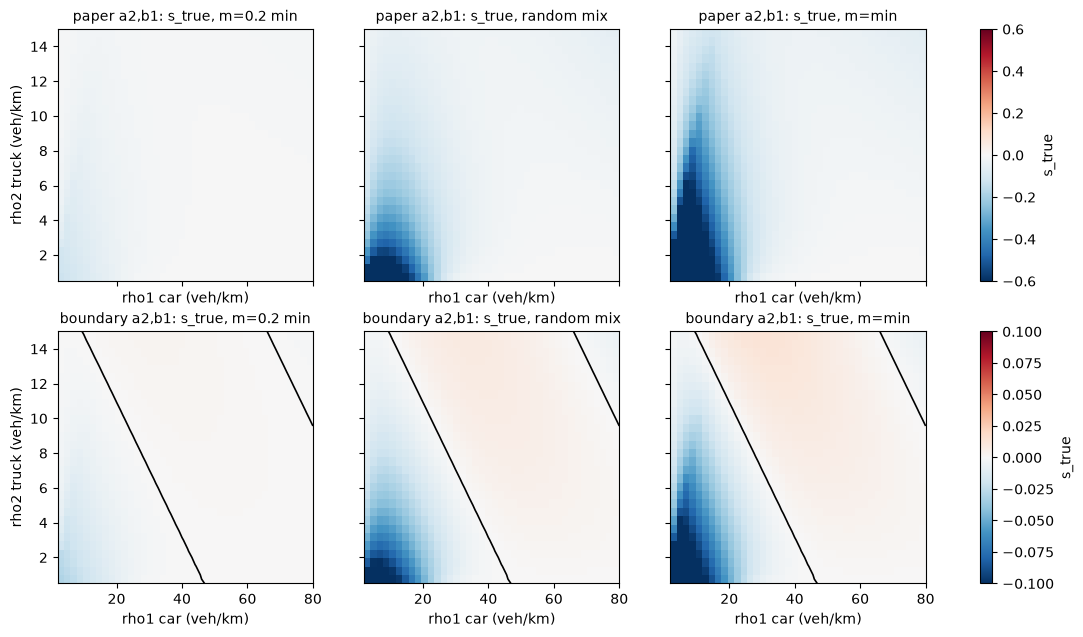

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.2), sharex=True, sharey=True)
LABELS = [('m=0.2min', 's_true, m=0.2 min'), ('random', 's_true, random mix'), ('m=min', 's_true, m=min')]
for row, (name, vmax) in enumerate([('paper', 0.6), ('boundary', 0.1)]):
    for col, (key, title) in enumerate(LABELS):
        im = show_map(axes[row, col], grids_2a[(name, key)], f'{name} a2,b1: {title}', vmax, contour=True)
    plt.colorbar(im, ax=axes[row, :].tolist(), label='s_true')
    axes[row, 0].set_ylabel('rho2 truck (veh/km)')
plt.savefig(OUT_Q1 / 'q1_2a_arrangement.png', dpi=130, bbox_inches='tight'); plt.show()

### 比率を固定して比べる

$\rho_1,\rho_2$ の地図では、比率と混み具合が一緒に動いてしまう。そこで、比率を固定して横軸を全体密度にし、**並びだけを変えた図**と**比率だけを変えた図**に分ける。

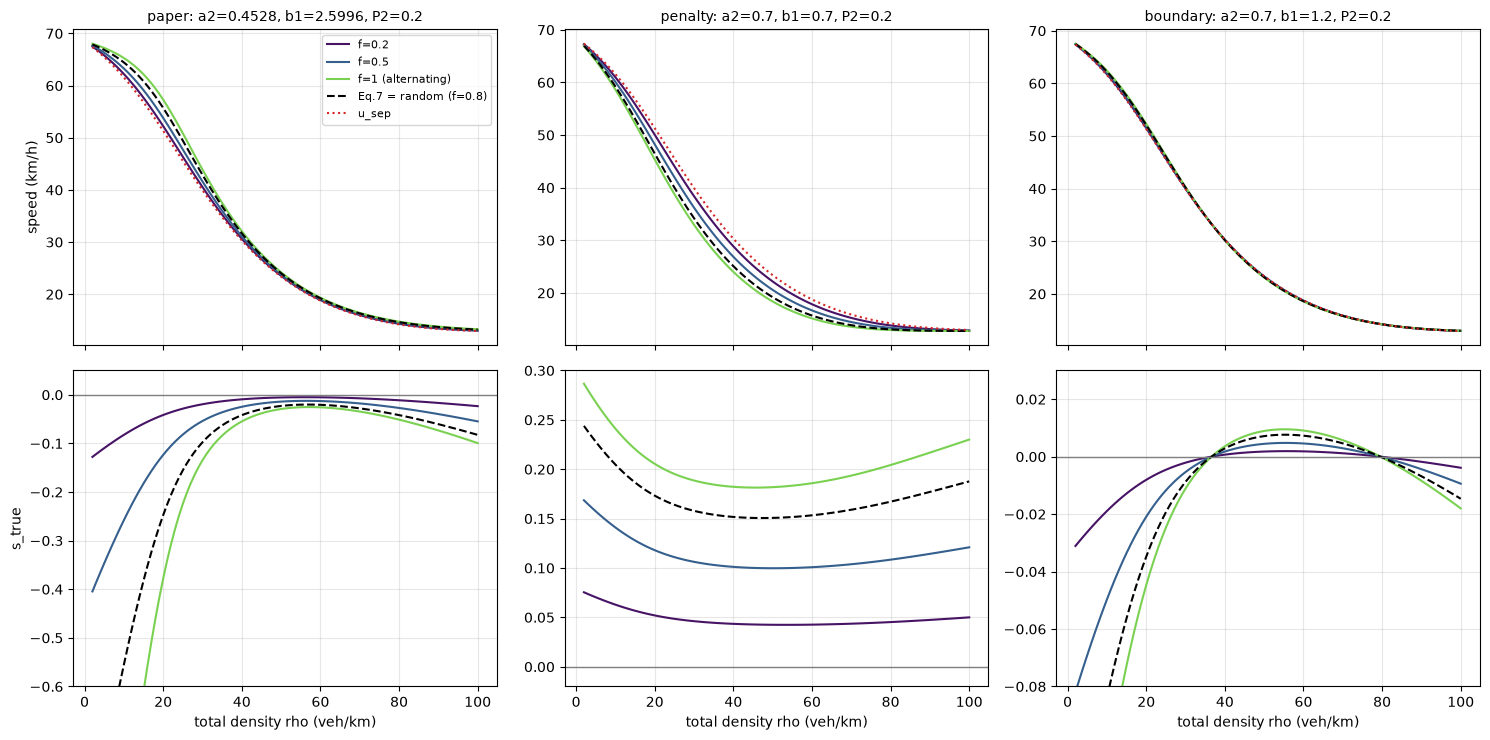

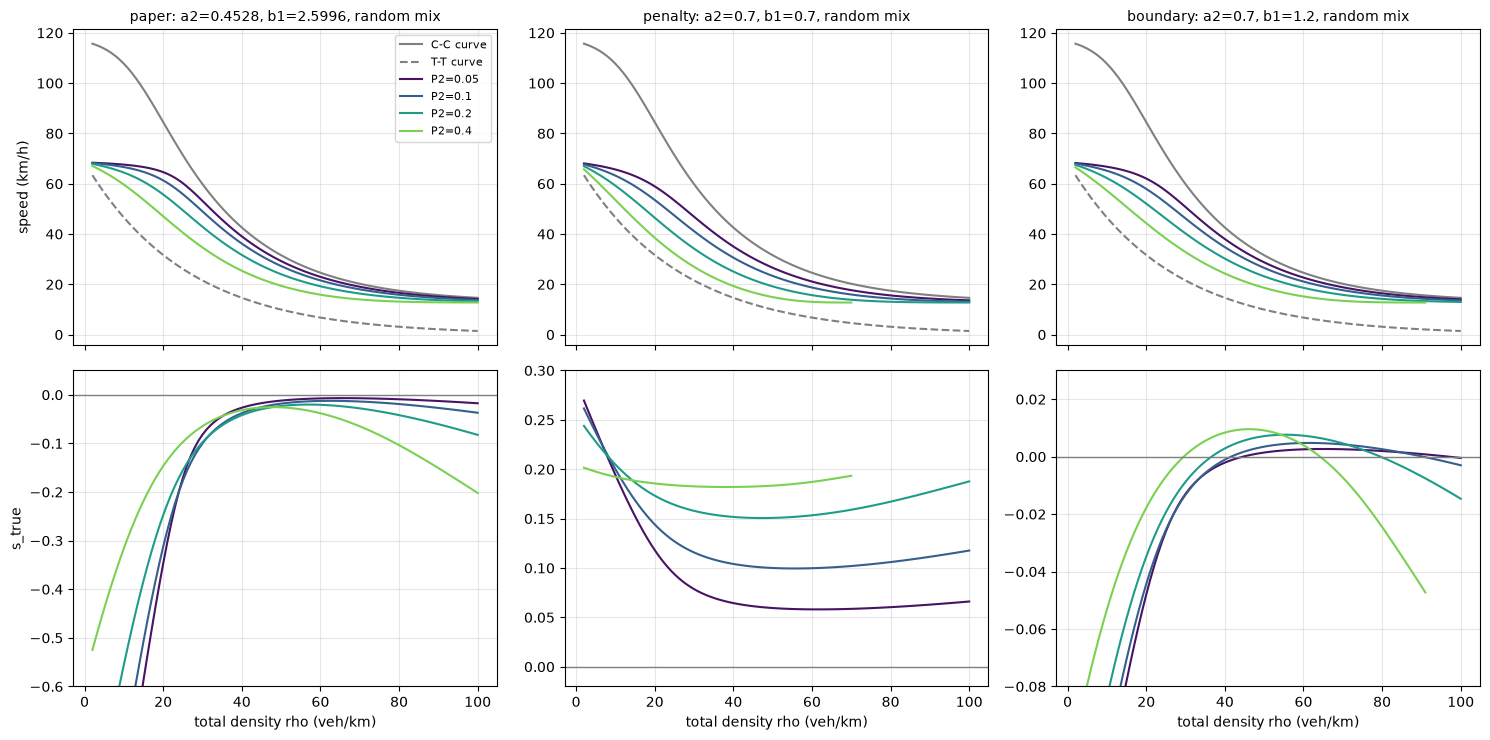

In [ ]:
#比率を固定して、全体密度を動かす。名目速度関数は論文形
RHO = np.linspace(2, 100, 99)
LINE_SETS = ['paper', 'penalty', 'boundary']
P2_FIX = 0.2
F_LEVELS = [(0.2, 'f=0.2'), (0.5, 'f=0.5'), (1.0, 'f=1 (alternating)')]
P2_LEVELS = [0.05, 0.1, 0.2, 0.4]
ramp = plt.cm.viridis(np.linspace(0.05, 0.8, 4))
nominal_of = {n: make_paper_nominal(CAR_PARAMS, TRUCK_PARAMS, *SCALE_SETS[n]) for n in LINE_SETS}

#(1) 比率を固定して、並び f だけを変える
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True)
for col, name in enumerate(LINE_SETS):
    w = nominal_of[name]
    eq = eq7_ratio_line(w, RHO, P2_FIX)
    for (f, label), color in zip(F_LEVELS, ramp[[0, 1, 3]]):
        line = ratio_line(w, RHO, P2_FIX, f)
        axes[0, col].plot(RHO, line['v'], color=color, label=label)
        axes[1, col].plot(RHO, line['s'], color=color, label=label)
    axes[0, col].plot(RHO, eq['v'], color='k', ls='--', label=f'Eq.7 = random (f={1 - P2_FIX:.1f})')
    axes[1, col].plot(RHO, eq['s'], color='k', ls='--', label=f'Eq.7 = random (f={1 - P2_FIX:.1f})')
    axes[0, col].plot(RHO, line['u_sep'], color='tab:red', ls=':', label='u_sep')
    axes[1, col].axhline(0, color='gray', lw=1)
    axes[0, col].set_title(f'{name}: a2={SCALE_SETS[name][0]}, b1={SCALE_SETS[name][1]}, P2={P2_FIX}', fontsize=10)
    axes[1, col].set_xlabel('total density rho (veh/km)')
    for ax in axes[:, col]:
        ax.grid(alpha=.3)
axes[0, 0].set_ylabel('speed (km/h)'); axes[1, 0].set_ylabel('s_true')
axes[0, 0].legend(fontsize=8)
axes[1, 0].set_ylim(-0.6, 0.05); axes[1, 1].set_ylim(-0.02, 0.3); axes[1, 2].set_ylim(-0.08, 0.03)
plt.tight_layout(); plt.savefig(OUT_Q1 / 'q1_2a_lines_by_m.png', dpi=130); plt.show()

#(2) 並びはランダム混合のまま、比率 P2 だけを変える。上段に C-C と T-T の曲線を重ねる
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True)
for col, name in enumerate(LINE_SETS):
    w = nominal_of[name]
    axes[0, col].plot(RHO, u_nominal(w, CAR, CAR, RHO), color='gray', label='C-C curve')
    axes[0, col].plot(RHO, u_nominal(w, TRUCK, TRUCK, RHO), color='gray', ls='--', label='T-T curve')
    for p2, color in zip(P2_LEVELS, ramp):
        line = ratio_line(w, RHO, p2)
        axes[0, col].plot(RHO, line['v'], color=color, label=f'P2={p2}')
        axes[1, col].plot(RHO, line['s'], color=color, label=f'P2={p2}')
    axes[1, col].axhline(0, color='gray', lw=1)
    axes[0, col].set_title(f'{name}: a2={SCALE_SETS[name][0]}, b1={SCALE_SETS[name][1]}, random mix', fontsize=10)
    axes[1, col].set_xlabel('total density rho (veh/km)')
    for ax in axes[:, col]:
        ax.grid(alpha=.3)
axes[0, 0].set_ylabel('speed (km/h)'); axes[1, 0].set_ylabel('s_true')
axes[0, 0].legend(fontsize=8)
axes[1, 0].set_ylim(-0.6, 0.05); axes[1, 1].set_ylim(-0.02, 0.3); axes[1, 2].set_ylim(-0.08, 0.03)
plt.tight_layout(); plt.savefig(OUT_Q1 / 'q1_2a_lines_by_ratio.png', dpi=130); plt.show()

In [ ]:
#比率ごとに、Eq.7 と正解の差をまとめる
rows = []
for name in LINE_SETS:
    w = nominal_of[name]
    for p2 in P2_LEVELS:
        eq = eq7_ratio_line(w, RHO, p2)
        for f in (0.2, 0.5, 1.0):
            line = ratio_line(w, RHO, p2, f)
            c = compare(line['v'], line['s'], eq['v'], eq['s'])
            rows.append({'a2,b1': name, 'P2': p2, 'f': f, 'f_random': max(p2, 1 - p2),
                         'du_abs_max': c['du_abs_max'], 'ds_abs_max': c['ds_abs_max'], 'sign_match': c['sign_match']})
table_lines = pd.DataFrame(rows)
table_lines.round(3)

,"a2,b1",P2,f,f_random,du_abs_max,ds_abs_max,sign_match
0,paper,0.05,0.2,0.95,3.130,1.165,1.0
1,paper,0.05,0.5,0.95,2.047,0.886,1.0
2,paper,0.05,1.0,0.95,0.276,0.177,1.0
3,paper,0.10,0.2,0.90,3.555,1.009,1.0
4,paper,0.10,0.5,0.90,2.228,0.730,1.0
5,paper,0.10,1.0,0.90,0.683,0.329,1.0
6,paper,0.20,0.2,0.80,3.486,0.754,1.0
7,paper,0.20,0.5,0.80,1.920,0.478,1.0
8,paper,0.20,1.0,0.80,1.582,0.573,1.0
9,paper,0.40,0.2,0.60,2.445,0.399,1.0


**②a の結果**

- $s=m\,B(v)/L$ は数値でも成り立つ（最大差 1.48e-13）。
- **並びを変えても、s の符号は全点で Eq.7 と一致した**（符号が変わる boundary の組を含む）。図の下段でも、$s=0$ の線の位置は m によらず同じである。これは上の式の通りで、並びは s の符号の不安定さの原因にならない。
- ずれるのは大きさである。論文の a2, b1 で $|\Delta u^*|$ は最大 4.1 km/h、$|\Delta s|$ は最大 0.90 で、大きな差は低密度の領域に集中する。s は m に比例するので、隊列が多い道路（m が小さい）では Eq.7 は $|s|$ を過大に見積もる。
- **比率を固定した図**: 並びだけを変えると、$s=0$ になる全体密度は変わらない（$P_2=0.2$ の boundary で、図から読んで約 37 と約 80 veh/km）。上段では、m によらず $v_{true}$ が $u_{sep}$ の同じ側にある。
- **比率は s の大きさも符号の境界も動かす**。boundary の組で $s>0$ になる密度の範囲は、$P_2$ で変わる。penalty の組で全体密度 60 veh/km の s は、$P_2=0.05$ で約 0.06、$P_2=0.2$ で約 0.15 である（図から読んだ値）。Eq.7 はこの比率の効果を式に含むので、ずれの原因は比率ではなく並びである。
- Eq.7 との差は、ランダム混合 $f=\max(P_2,1-P_2)$ から離れるほど大きい。$P_2=0.05$ なら交互（$f=1$）との差は小さく（$|\Delta u^*|$ 最大 0.28 km/h）、$f=0.2$ との差は大きい（3.13 km/h）。$P_2=0.4$ では交互との差も 3.35 km/h ある。
- 論文形の速度には下限 `ub`（約 12.8 km/h）があるので、高密度側の値はこの下限の影響を受ける。途中で切れている線は、解がなくなる点である。
- ここで調べたのは1車線の並びだけで、車線ごとに混ざり方が違う場合は含まない。

## 7. ②b-1: 関数形だけを崩す（OV形 `scale`）

真の曲線は tanh で、スケーリング $V_{ij}(h)=V_{ii}(a_{ij}h)$ は厳密に成り立つ。そこから密度 2〜100 veh/km の点を400点取り、NGSIM と同じ関数（ISRES、L1 誤差、既定の探索範囲）で論文形をフィットする。

- **own + fit a2,b1**: C-C・T-T は真の曲線のまま a2, b1 だけフィット。関数形の誤差がないので、正解に一致するはず（検算）。
- **full fit**: logistic・Underwood と a2, b1 をすべてフィット。ISRES は確率的なので、乱数を5通り変えて平均する。

OV形の曲線は上限 90 km/h 付近でほぼ平らになり、車間が速度で大きく変わるので、$v_{true}<60$ km/h の点だけの集計も並べる。

In [ ]:
SEEDS = range(5)


def run_truth(w, rho_max=100.0):
    #1つの真の名目速度関数に対して、全部のアルゴリズムを評価する
    df = sample_curves(w, rho_max=rho_max)
    V, S = truth_grid(w, grid_r1, grid_r2)
    algo, a2_own, b1_own = fit_scaling_only(w, df)
    U_own, s_own = own_curve_eq7_grid(algo, grid_r1, grid_r2)
    res = {'V': V, 'S': S, 'U_own': U_own, 's_own': s_own, 'a2_own': a2_own, 'b1_own': b1_own, 'fits': []}
    for seed in SEEDS:
        fit = fit_paper_form(df, seed)
        for sc in ('printed', 'inverted'):
            fit[sc] = eq7_grid(fit['nominal'], grid_r1, grid_r2, sc)
        res['fits'].append(fit)
    return res


def summarize(res, name, v_below=None):
    #フィットの列は5通りの乱数の平均
    V, S = res['V'], res['S']
    rows = [{'truth': name, 'algorithm': 'own + fit a2,b1', 'a2_hat': res['a2_own'], 'b1_hat': res['b1_own'],
             **compare(V, S, res['U_own'], res['s_own'], v_below)}]
    for sc in ('printed', 'inverted'):
        r = pd.DataFrame([{'a2_hat': f['a2'], 'b1_hat': f['b1'], **compare(V, S, *f[sc], v_below)} for f in res['fits']])
        rows.append({'truth': name, 'algorithm': f'full fit, {sc}', **r.mean().to_dict()})
    return rows


results = {n: run_truth(make_ov_nominal(form='scale', scale={(CAR, TRUCK): a, (TRUCK, CAR): b}))
           for n, (a, b) in SCALE_SETS.items()}

cols = ['truth', 'algorithm', 'a2_hat', 'b1_hat', 'solved', 'du_mean', 'du_abs_max', 'ds_mean', 'ds_abs_max',
        's_true_pos', 's_alg_pos', 'sign_match']
table_2b1 = pd.DataFrame([x for n, res in results.items() for x in summarize(res, n)])
table_2b1[cols].round(3)

,truth,algorithm,a2_hat,b1_hat,solved,du_mean,du_abs_max,ds_mean,ds_abs_max,s_true_pos,s_alg_pos,sign_match
0,neutral,"own + fit a2,b1",1.000,1.000,1.000,-0.000,0.000,0.000,0.000,0.000,0.990,NaN
1,neutral,"full fit, printed",0.997,1.000,0.904,-4.644,28.950,0.000,0.001,0.000,0.400,NaN
2,neutral,"full fit, inverted",0.997,1.000,0.904,-4.616,28.911,-0.000,0.001,0.000,0.600,NaN
3,paper,"own + fit a2,b1",0.453,2.600,1.000,-0.000,0.000,0.000,0.000,0.930,0.930,1.000
4,paper,"full fit, printed",0.452,3.269,0.850,-2.753,26.466,-0.013,0.125,0.915,0.682,0.767
5,paper,"full fit, inverted",0.452,3.269,0.890,-15.784,53.822,0.197,0.601,0.920,1.000,0.920
6,mild,"own + fit a2,b1",0.600,1.500,1.000,0.000,0.000,-0.000,0.000,0.918,0.918,1.000
7,mild,"full fit, printed",0.600,1.484,0.874,-4.171,28.240,0.004,0.068,0.905,0.786,0.881
8,mild,"full fit, inverted",0.600,1.484,0.916,-5.936,31.412,0.024,0.210,0.910,0.951,0.861
9,penalty,"own + fit a2,b1",0.700,0.700,1.000,-0.000,0.000,0.000,0.000,1.000,1.000,1.000


In [ ]:
#v_true < 60 km/h の点だけ
table_2b1_cong = pd.DataFrame([x for n, res in results.items() for x in summarize(res, n, v_below=60.0)])
table_2b1_cong[cols].round(3)

,truth,algorithm,a2_hat,b1_hat,solved,du_mean,du_abs_max,ds_mean,ds_abs_max,s_true_pos,s_alg_pos,sign_match
0,neutral,"own + fit a2,b1",1.000,1.000,1.000,-0.000,0.000,0.000,0.000,0.0,1.000,NaN
1,neutral,"full fit, printed",0.997,1.000,0.876,-2.047,15.308,0.000,0.001,0.0,0.400,NaN
2,neutral,"full fit, inverted",0.997,1.000,0.876,-2.024,15.249,-0.000,0.001,0.0,0.600,NaN
3,paper,"own + fit a2,b1",0.453,2.600,1.000,-0.000,0.000,0.000,0.000,1.0,1.000,1.000
4,paper,"full fit, printed",0.452,3.269,0.815,-1.330,10.795,0.002,0.116,1.0,0.885,0.885
5,paper,"full fit, inverted",0.452,3.269,0.864,-9.307,38.964,0.163,0.299,1.0,1.000,1.000
6,mild,"own + fit a2,b1",0.600,1.500,1.000,0.000,0.000,-0.000,0.000,1.0,1.000,1.000
7,mild,"full fit, printed",0.600,1.484,0.841,-2.100,14.143,0.010,0.058,1.0,0.992,0.992
8,mild,"full fit, inverted",0.600,1.484,0.894,-2.589,18.049,0.008,0.044,1.0,0.935,0.935
9,penalty,"own + fit a2,b1",0.700,0.700,1.000,-0.000,0.000,0.000,0.000,1.0,1.000,1.000


In [ ]:
#フィットの出来と、乱数によるばらつき
pd.DataFrame([{'seed': i, **{k: f[k] for k in ('mae_cc', 'mae_tt', 'mae_ct', 'mae_tc', 'a2', 'b1')},
               'cc_uf': f['cc']['uf'], 'cc_ub': f['cc']['ub'], 'cc_rhoc': f['cc']['rhoc'], 'cc_theta2': f['cc']['theta2'],
               'tt_uf': f['tt']['uf'], 'tt_rhoc': f['tt']['rhoc']}
              for i, f in enumerate(results['mild']['fits'])]).round(3)

,seed,mae_cc,mae_tt,mae_ct,mae_tc,a2,b1,cc_uf,cc_ub,cc_rhoc,cc_theta2,tt_uf,tt_rhoc
0,0,3.142,10.922,2.651,12.734,0.601,1.484,128.300,4.021,34.498,1.138,150.0,17.669
1,1,3.922,10.922,4.067,12.734,0.605,1.484,128.668,6.237,60.615,9.249,150.0,17.669
2,2,3.748,10.922,2.429,12.734,0.589,1.484,126.886,1.536,22.533,0.421,150.0,17.669
3,3,3.954,10.922,4.167,12.734,0.600,1.484,129.828,6.407,76.482,36.973,150.0,17.669
4,4,3.897,10.922,4.105,12.734,0.603,1.484,129.907,6.456,63.203,11.511,150.0,17.669


In [ ]:
#全フィットの結果がフィットの乱数でどれだけ変わるか（印刷版）
rows = []
for name, res in results.items():
    per_seed = pd.DataFrame([compare(res['V'], res['S'], *f['printed']) for f in res['fits']])
    rows.append({'truth': name, 'sign_match_min': per_seed['sign_match'].min(), 'sign_match_max': per_seed['sign_match'].max(),
                 'solved_min': per_seed['solved'].min(), 'solved_max': per_seed['solved'].max(),
                 'du_mean_min': per_seed['du_mean'].min(), 'du_mean_max': per_seed['du_mean'].max()})
pd.DataFrame(rows).round(3)

,truth,sign_match_min,sign_match_max,solved_min,solved_max,du_mean_min,du_mean_max
0,neutral,NaN,NaN,0.794,1.0,-5.921,-2.663
1,paper,0.729,0.804,0.702,1.0,-3.903,-0.807
2,mild,0.843,0.954,0.744,1.0,-5.451,-2.172
3,penalty,1.000,1.000,0.748,1.0,-5.656,-2.228
4,boundary,0.956,0.990,0.761,1.0,-5.739,-2.389


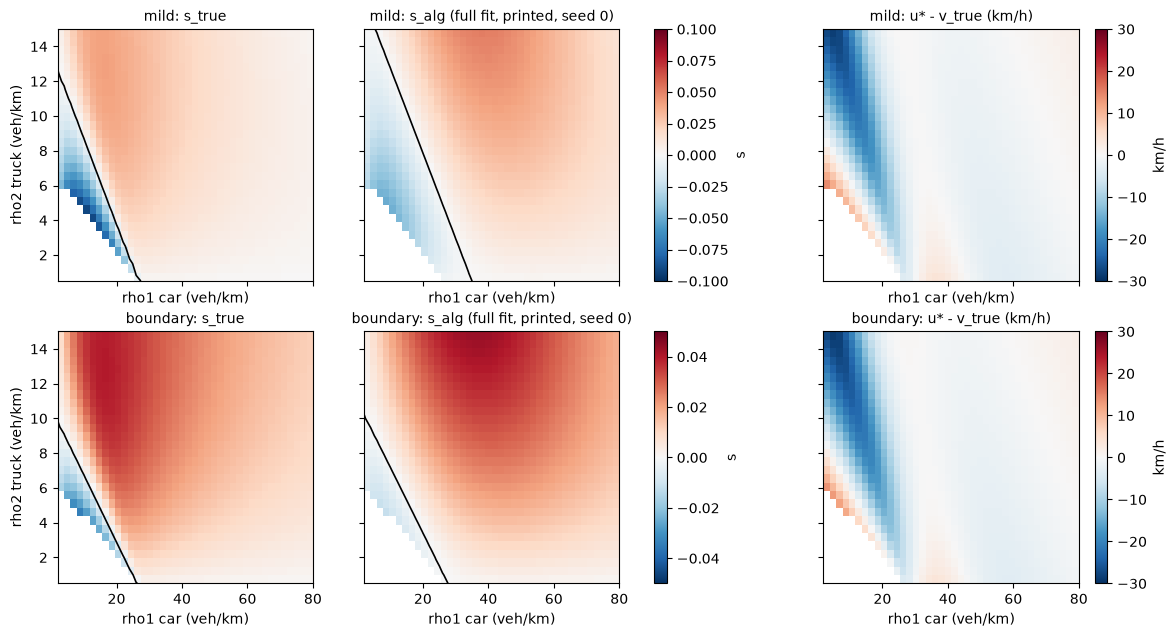

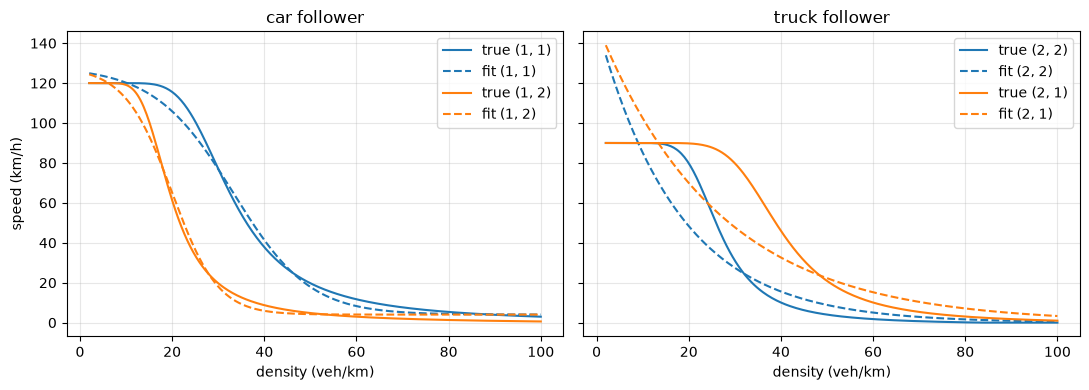

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.2), sharex=True, sharey=True)
for row, (name, vmax) in enumerate([('mild', 0.1), ('boundary', 0.05)]):
    res = results[name]
    U, s = res['fits'][0]['printed']
    im = show_map(axes[row, 0], res['S'], f'{name}: s_true', vmax, contour=True)
    show_map(axes[row, 1], np.where(np.isfinite(res['V']), s, np.nan), f'{name}: s_alg (full fit, printed, seed 0)', vmax, contour=True)
    plt.colorbar(im, ax=axes[row, :2].tolist(), label='s')
    im2 = show_map(axes[row, 2], U - res['V'], f'{name}: u* - v_true (km/h)', 30)
    plt.colorbar(im2, ax=axes[row, 2], label='km/h')
    axes[row, 0].set_ylabel('rho2 truck (veh/km)')
plt.savefig(OUT_Q1 / 'q1_2b1_shape.png', dpi=130, bbox_inches='tight'); plt.show()

w = make_ov_nominal(form='scale', scale={(CAR, TRUCK): 0.6, (TRUCK, CAR): 1.5})
algo = results['mild']['fits'][0]['nominal']
rho = np.linspace(2, 100, 300)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, pairs, title in [(axes[0], [(1, 1), (1, 2)], 'car follower'), (axes[1], [(2, 2), (2, 1)], 'truck follower')]:
    for p, color in zip(pairs, ['tab:blue', 'tab:orange']):
        ax.plot(rho, u_nominal(w, *p, rho), color=color, label=f'true {p}')
        ax.plot(rho, u_nominal(algo, *p, rho), color=color, ls='--', label=f'fit {p}')
    ax.set_title(title); ax.set_xlabel('density (veh/km)'); ax.grid(alpha=.3); ax.legend()
axes[0].set_ylabel('speed (km/h)')
plt.tight_layout(); plt.savefig(OUT_Q1 / 'q1_2b1_fit_curves.png', dpi=130); plt.show()

**②b-1 の結果**

- 検算: own + fit a2,b1 は a2, b1 を正しく戻し、$u^*$ も s も正解に一致する。
- 関数形だけを崩すと $u^*$ は大きくずれる。印刷版で $|\Delta u^*|$ は最大約 26〜30 km/h、$v_{true}<60$ km/h でも約 11〜17 km/h ある。主な原因はトラック側で、Underwood は tanh の平らな部分を表せず、`uf` が探索範囲の上限 150 km/h に張り付いた（テスト MAE 約 11 km/h）。
- それでも**印刷版の符号の一致率は 77〜100%** で、$v_{true}<60$ km/h では 89〜100% だった。a2 は真の値にほぼ戻るが、b1 は paper の組で 2.60 → 3.27 とずれる。
- **反転版は組によって全く当たらない**。penalty の組では一致率 0%、boundary の組では 32% だった。paper の組では全点 s>0、penalty の組では全点 s<0 と、真の s と関係なく符号が a2, b1 で決まっていて、真の s と同じ符号の組でだけ当たって見える。
- 同じ a2, b1 でも、基準の曲線が違うと s の符号は変わる。paper の a2, b1 は論文形では全点 s<0 だが、OV形 `scale` では 93% の点で s>0 になる。
- **全フィットの結果には、関数形の影響とフィットの不安定さが混ざっている**。logistic のパラメータは乱数で大きく変わり（`rhoc` が 22〜76）、L1 誤差が近い別の解に落ちている。印刷版の符号の一致率も乱数で変わり（paper 0.73〜0.80、mild 0.84〜0.95、boundary 0.96〜0.99、penalty 1.00）、Eq.7 が解ける点の割合は 0.70〜1.00 と大きく動く。上の表の値は5通りの乱数の平均である。

## 8. ②b-2: スケーリングだけを崩す（OV形 `gap`）

真の曲線は車長の差だけで C-T と C-C が違う。$B(v)\equiv 0$ なので $s_{true}\equiv 0$ であり、**s の信号が出れば、すべてアルゴリズムが作ったもの**である。

- C-C・T-T は真の曲線のまま a2, b1 だけフィットする（**own + fit a2,b1**）。これが仮定2だけを崩した比較。
- 参考として、論文形をすべてフィットした場合（**full fit**、仮定1も崩れる）も並べる。
- データの密度範囲で a2, b1 が変わるかも確かめる。

In [ ]:
gap = make_ov_nominal()
res_gap = run_truth(gap)
table_2b2 = pd.DataFrame(summarize(res_gap, 'gap') + summarize(res_gap, 'gap, v<60', v_below=60.0))
cols_gap = ['truth', 'algorithm', 'a2_hat', 'b1_hat', 'solved', 'du_mean', 'du_abs_max', 's_alg_min', 's_alg_max', 's_alg_pos', 'false_signal']
print(f"max|s_true| = {np.nanmax(np.abs(res_gap['S'])):.1e}")
table_2b2[cols_gap].round(3)

max|s_true| = 9.3e-09


,truth,algorithm,a2_hat,b1_hat,solved,du_mean,du_abs_max,s_alg_min,s_alg_max,s_alg_pos,false_signal
0,gap,"own + fit a2,b1",0.782,1.280,1.000,0.273,0.892,-0.076,-0.000,0.000,0.338
1,gap,"full fit, printed",0.765,1.302,0.893,-4.000,27.943,-0.059,0.023,0.473,0.362
2,gap,"full fit, inverted",0.765,1.302,0.910,-6.284,31.524,-0.011,0.084,0.964,0.777
3,"gap, v<60","own + fit a2,b1",0.782,1.280,1.000,0.251,0.801,-0.017,-0.000,0.000,0.259
4,"gap, v<60","full fit, printed",0.765,1.302,0.861,-1.843,13.919,-0.023,0.023,0.636,0.156
5,"gap, v<60","full fit, inverted",0.765,1.302,0.884,-3.033,18.683,-0.011,0.051,0.951,0.705


In [ ]:
#データの密度範囲を変える（a2, b1 だけのフィット）
rows = []
for rho_max in (40.0, 60.0, 80.0, 100.0, 150.0):
    df = sample_curves(gap, rho_max=rho_max)
    algo_r, a2_r, b1_r = fit_scaling_only(gap, df)
    U_r, s_r = own_curve_eq7_grid(algo_r, grid_r1, grid_r2)
    c = compare(res_gap['V'], res_gap['S'], U_r, s_r)
    rows.append({'rho_max': rho_max, 'a2_hat': a2_r, 'b1_hat': b1_r, 'du_abs_max': c['du_abs_max'],
                 's_alg_min': c['s_alg_min'], 's_alg_max': c['s_alg_max'], 'false_signal': c['false_signal']})
pd.DataFrame(rows).round(3)

,rho_max,a2_hat,b1_hat,du_abs_max,s_alg_min,s_alg_max,false_signal
0,40.0,0.799,1.237,0.625,-0.064,-0.0,0.206
1,60.0,0.784,1.267,0.727,-0.071,-0.0,0.267
2,80.0,0.781,1.276,0.782,-0.074,-0.0,0.290
3,100.0,0.782,1.280,0.892,-0.076,-0.0,0.338
4,150.0,0.782,1.282,0.910,-0.076,-0.0,0.342


In [ ]:
#OV形の仮置きの値を1つずつ変える（a2, b1 だけのフィット）。真の s はどの値でも0
BASE = {'l0': 12.5, 'c': 2.0, 'len_t': 12.0, 'vmax_t': 90.0}
CASES = [{}] + [{'l0': x} for x in (6.25, 25.0)] + [{'c': x} for x in (1.0, 4.0)] + \
        [{'len_t': x} for x in (8.0, 16.0)] + [{'vmax_t': x} for x in (70.0, 120.0)]
rows = []
for case in CASES:
    q = {**BASE, **case}
    w = make_ov_nominal(vmax={CAR: 120.0, TRUCK: q['vmax_t']}, length={CAR: 4.5, TRUCK: q['len_t']},
                        shape={'l0': q['l0'], 'c': q['c']})
    V_q, S_q = truth_grid(w, grid_r1, grid_r2)
    algo_q, a2_q, b1_q = fit_scaling_only(w, sample_curves(w))
    U_q, s_q = own_curve_eq7_grid(algo_q, grid_r1, grid_r2)
    c_all, c_c = compare(V_q, S_q, U_q, s_q), compare(V_q, S_q, U_q, s_q, v_below=60.0)
    rows.append({'changed': str(case) if case else 'base', 'a2_hat': a2_q, 'b1_hat': b1_q,
                 'n_valid': c_all['n_truth'], 's_min': c_all['s_alg_min'], 's_max': c_all['s_alg_max'], 'false_signal': c_all['false_signal'],
                 's_min_v<60': c_c['s_alg_min'], 's_max_v<60': c_c['s_alg_max'], 'false_signal_v<60': c_c['false_signal']})
pd.DataFrame(rows).round(3)

,changed,a2_hat,b1_hat,n_valid,s_min,s_max,false_signal,s_min_v<60,s_max_v<60,false_signal_v<60
0,base,0.782,1.280,1130,-0.076,-0.000,0.338,-0.017,-0.000,0.259
1,{'l0': 6.25},0.683,1.461,950,-0.102,-0.000,0.383,-0.015,-0.000,0.152
2,{'l0': 25.0},0.863,1.159,1184,-0.049,-0.000,0.159,-0.013,-0.000,0.137
3,{'c': 1.0},0.687,1.452,1087,-0.136,-0.000,0.470,-0.017,-0.000,0.278
4,{'c': 4.0},0.876,1.142,1166,-0.033,-0.000,0.076,-0.011,-0.000,0.052
5,{'len_t': 8.0},0.883,1.132,1128,-0.039,-0.000,0.105,-0.005,-0.000,0.000
6,{'len_t': 16.0},0.703,1.424,1131,-0.104,-0.000,0.590,-0.033,-0.000,0.575
7,{'vmax_t': 70.0},0.782,1.280,1119,-0.085,-0.001,0.606,-0.020,-0.001,0.525
8,{'vmax_t': 120.0},0.782,1.280,1188,-0.014,0.011,0.069,-0.014,0.001,0.089


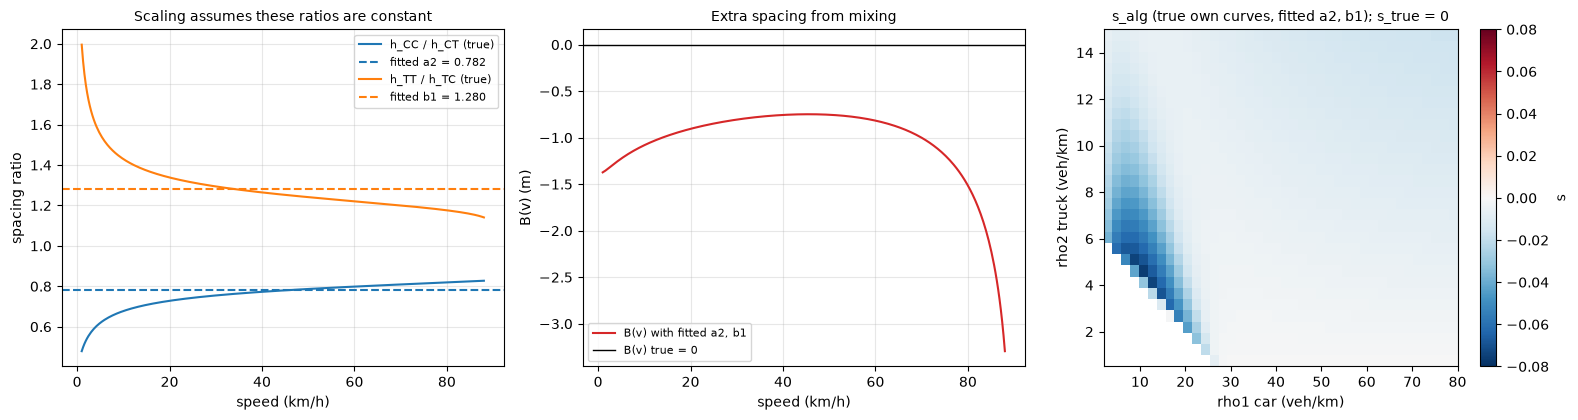

In [ ]:
v = np.linspace(1, 88, 300)
hcc, hct, htt, htc = [np.array([float(h_eq(gap, *p, x)) for x in v]) for p in [(1, 1), (1, 2), (2, 2), (2, 1)]]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].plot(v, hcc / hct, color='tab:blue', label='h_CC / h_CT (true)')
axes[0].axhline(res_gap['a2_own'], color='tab:blue', ls='--', label=f"fitted a2 = {res_gap['a2_own']:.3f}")
axes[0].plot(v, htt / htc, color='tab:orange', label='h_TT / h_TC (true)')
axes[0].axhline(res_gap['b1_own'], color='tab:orange', ls='--', label=f"fitted b1 = {res_gap['b1_own']:.3f}")
axes[0].set_xlabel('speed (km/h)'); axes[0].set_ylabel('spacing ratio'); axes[0].grid(alpha=.3); axes[0].legend(fontsize=8)
axes[0].set_title('Scaling assumes these ratios are constant', fontsize=10)

scaled = (hcc / res_gap['a2_own'] + htt / res_gap['b1_own']) - (hcc + htt)
axes[1].plot(v, scaled, color='tab:red', label='B(v) with fitted a2, b1')
axes[1].axhline(0, color='k', lw=1, label='B(v) true = 0')
axes[1].set_xlabel('speed (km/h)'); axes[1].set_ylabel('B(v) (m)'); axes[1].grid(alpha=.3); axes[1].legend(fontsize=8)
axes[1].set_title('Extra spacing from mixing', fontsize=10)

im = show_map(axes[2], np.where(np.isfinite(res_gap['V']), res_gap['s_own'], np.nan), 's_alg (true own curves, fitted a2, b1); s_true = 0', 0.08)
axes[2].set_ylabel('rho2 truck (veh/km)'); plt.colorbar(im, ax=axes[2], label='s')
plt.tight_layout(); plt.savefig(OUT_Q1 / 'q1_2b2_scaling.png', dpi=130); plt.show()

**②b-2 の結果**

- **車長の差だけで、$a_2<1$、$b_1>1$ が推定された**（a2 = 0.782、b1 = 1.280）。この傾向は、試したすべての密度範囲と仮置きの値で同じだった。したがって、$a_2<1$、$b_1>1$ だけを根拠に「先行車によって運転の仕方が違う」とは言えない。
- 真の比 $h_{CC}/h_{CT}$、$h_{TT}/h_{TC}$ は速度で変わるが、スケーリングはこれを定数に置き換える。そのため $B(v)$ が0にならず、**真の s は0なのに負の s が出る**。a2, b1 のフィットで、$|s|>0.01$ の点は 34%、最小は −0.076 だった（$v_{true}<60$ km/h では 26%、−0.017）。
- $u^*$ の誤差は最大 0.89 km/h と小さい。s は $u^*$ の小さなずれにも反応するので、速度が合っていることは s が正しいことの保証にならない。
- 論文形をすべてフィットすると（仮定1も崩れる）、印刷版の符号は混ざる。**反転版は 96% の点で s>0 を出す**。真の s は0なので、この正の s はすべて作られたものである。
- 仮置きの値を変えると偽の信号の大きさは変わる（$|s|>0.01$ の点が 7〜61%）。符号はトラックの最高速度を 120 km/h にした場合を除いて負だった。トラックの車長が長いほど、最高速度が低いほど大きい傾向がある。

## 9. まとめ

| 崩した仮定 | $\Delta u^*$ | s の符号 |
|---|---|---|
| ランダム混合（②a） | 最大 約 4.5 km/h | 変わらない（式でも数値でも） |
| 関数形（②b-1） | 最大 約 30 km/h | 印刷版は平均 77〜100% 一致（フィットの乱数で変わる）。反転版は 0〜92% |
| スケーリング（②b-2） | a2, b1 のみのフィットで最大 0.89 km/h | 真の0に対して、偽の負の信号が出る |

**注意**: OV形の値はすべて仮置きで、データにノイズはなく、フィットの密度範囲（2〜100 veh/km）も仮の設定である。NGSIM の s と大きさを直接比べることはできない。NGSIM で論文の固定値を使うフィットとも手順が違う（ここでは全パラメータを自由にしている）。